# OLIVES data audit

**Purpose:** This notebook checks downloaded OLIVES data matches what the paper describes, before any research experiments are done

[**Link to the source paper**](https://proceedings.neurips.cc/paper_files/paper/2022/file/3be60b4a739b95a07a944a1a2c41e05e-Paper-Datasets_and_Benchmarks.pdf)

**Expected Data as per source paper**
`PRIME evaluates Diabetic Retinopathy (DR) and TREX-DME evaluates Diabetic Macular Edema
(DME). The trials provide access to near-IR fundus images and OCT scans along with de-identified
Electronic Medical Records (EMR) data of 96 patients across an average of 66 weeks. Biomarkers
are retrospectively added to this data by experienced graders upon open adjudication.`

**Steps**
1. Inventory the image folders
2. Volumes and visit order
3. Find the label files
4. Check the biomarker labels
5. Check the clinical labels
6. Find duplicate volumes
7. Biomarker prevalence: first vs last visit
8. Image properties and visual checks
9. Write the summary

Every problem found is recorded with `flag(...)` and listed again at the end in `audit_outputs/anomalies.csv`.

In [2]:

from pathlib import Path
import os, re, hashlib, random, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Folder holding bscans
PROJECT   = Path(os.environ.get('OLIVES_PROJECT', '/Users/parvezali/Research Proposal'))
DATA_ROOT = Path(os.environ.get('OLIVES_ROOT', str(PROJECT / 'OLIVES')))
# Folder holding full_labels/ and ml_centric_labels/
LABEL_ROOT = Path(os.environ.get('OLIVES_LABELS', str(PROJECT / 'OLIVES_Dataset_Labels')))
OUT       = PROJECT / 'audit_outputs'
OUT.mkdir(exist_ok=True)

SEED = 0
random.seed(SEED); np.random.seed(SEED)
IMG_EXT = {'.png', '.tif', '.tiff', '.jpg', '.jpeg', '.bmp'}
pd.set_option('display.max_columns', 60, 'display.width', 200, 'display.max_colwidth', 80)

assert DATA_ROOT.exists(), f'Data folder not found: {DATA_ROOT}'
print('Data root :', DATA_ROOT, 'found' if DATA_ROOT else f'{DATA_ROOT} not found')
print('Labels    :', LABEL_ROOT, 'found' if LABEL_ROOT else f'{LABEL_ROOT} not found')
print('Outputs   :', OUT)

# Flag to log the anomalies found during this audit
ANOMALIES = []
def flag(check, detail, n=None):
    ANOMALIES.append({'check': check, 'detail': detail, 'count': n})
    print(f'[FLAG] {check}: {detail}' + (f'  (n={n})' if n is not None else ''))

# File paths represent a meaning full visit orders.
VISIT_RE = re.compile(r'^([WV])(\d+)$', re.I)
def visit_number(v):
    """'W104' -> 104 (weeks, PRIME), 'V22' -> 22 (visit number, TREX)."""
    m = VISIT_RE.match(str(v))
    return float(m.group(2)) if m else np.nan

def scan_from_stem(stem):
    d = re.findall(r'\d+', str(stem))
    return float(d[-1]) if d else np.nan

def study_of(trial):
    return 'PRIME' if 'prime' in str(trial).lower() else 'TREX'

def parse_parts(parts):
    """[trial, (cohort...), patient, visit, OD|OS, file] -> dict, or None if the layout differs."""
    parts = [p for p in parts if p not in ('', '.')]
    eyes = [i for i, p in enumerate(parts) if p.upper() in ('OD', 'OS')]
    if not eyes or eyes[-1] < 3:
        return None
    e = eyes[-1]
    return dict(trial=parts[0], cohort='/'.join(parts[1:e - 2]), patient=parts[e - 2],
                visit=parts[e - 1], eye=parts[e].upper(), file=parts[-1])

def read_table(p, **kw):
    return pd.read_csv(p, **kw) if p.suffix.lower() == '.csv' else pd.read_excel(p, **kw)

Data root : /Users/parvezali/Research Proposal/OLIVES found
Labels    : /Users/parvezali/Research Proposal/OLIVES_Dataset_Labels found
Outputs   : /Users/parvezali/Research Proposal/audit_outputs


## Step 1: Inventory the image folders
Walks every folder, parses `trial / (cohort) / patient / visit / eye / scan` from each image path, and lists every non-image file (e.g. the `sequence_*.npy` files).

In [2]:
rows, other = [], []
for dirpath, dirnames, filenames in os.walk(DATA_ROOT):
    dirnames.sort()
    rel = Path(dirpath).relative_to(DATA_ROOT).parts
    for fn in sorted(filenames):
        if fn.startswith('.'):
            continue
        p = Path(dirpath) / fn
        size = p.stat().st_size
        info = parse_parts(list(rel) + [fn]) if p.suffix.lower() in IMG_EXT else None
        if info is None:
            other.append({'file': str(p.relative_to(DATA_ROOT)), 'ext': p.suffix.lower() or '(none)', 'bytes': size})
            continue
        info.update(scan_idx=scan_from_stem(p.stem), path=str(p), bytes=size)
        rows.append(info)

img = pd.DataFrame(rows)
other = pd.DataFrame(other, columns=['file', 'ext', 'bytes'])
assert len(img), 'No OCT images found: check DATA_ROOT and the folder layout.'

img['study']     = img['trial'].map(study_of)
img['visit_num'] = img['visit'].map(visit_number)
img['pat_key']   = img['study'] + '|' + img['patient']
img['eye_key']   = img['pat_key'] + '|' + img['eye']
img['vol_key']   = img['eye_key'] + '|' + img['visit']
img.to_csv(OUT / 'image_index.csv', index=False)

print(f'B-scan images : {len(img):,}  ({img.bytes.sum() / 1e9:.2f} GB)')
print(f'Other files   : {len(other):,}  ({other.bytes.sum() / 1e9:.2f} GB)')
display(other.groupby('ext').agg(files=('file', 'size'), GB=('bytes', lambda b: round(b.sum() / 1e9, 3))))

stray_imgs = other[other.ext.isin(IMG_EXT)]
if len(stray_imgs):
    flag('folder layout', 'image files outside the trial/patient/visit/eye layout', len(stray_imgs))
    display(stray_imgs.head(10))

per_study = img.groupby('study').agg(patients=('pat_key', 'nunique'), eyes=('eye_key', 'nunique'),
                                     volumes=('vol_key', 'nunique'), bscans=('path', 'size'))
per_study.loc['ALL'] = [img.pat_key.nunique(), img.eye_key.nunique(), img.vol_key.nunique(), len(img)]
display(per_study)
print('Cohort sub-folders (eyes per cohort):')
display(img.groupby(['study', 'cohort']).eye_key.nunique().rename('eyes'))

found = {'patients': img.pat_key.nunique(), 'eyes': img.eye_key.nunique(),
         'PRIME eyes': img.loc[img.study == 'PRIME', 'eye_key'].nunique(),
         'TREX eyes': img.loc[img.study == 'TREX', 'eye_key'].nunique(),
         'volumes': img.vol_key.nunique(), 'B-scans': len(img)}
expected = {'patients': 87, 'eyes': 96, 'PRIME eyes': 40, 'TREX eyes': 56,
            'volumes': '1,268 (paper) / 1,590 (MIRAGE)', 'B-scans': '78,108-78,822 (sources disagree)'}
EXPECT = pd.DataFrame({'expected': expected, 'found': found})
display(EXPECT)
for k in ['patients', 'eyes', 'PRIME eyes', 'TREX eyes']:
    if found[k] != expected[k]:
        flag('counts', f'{k}: expected {expected[k]}, found {found[k]}')

B-scan images : 159,281  (44.49 GB)
Other files   : 3,583  (7.65 GB)


,files,GB
ext,,
.npy,1783,7.151
.tif,1800,0.495


[FLAG] folder layout: image files outside the trial/patient/visit/eye layout  (n=1800)


,file,ext,bytes
497,Prime_FULL/02-024/W28/OD 2/0.tif,.tif,250106
498,Prime_FULL/02-024/W28/OD 2/1.tif,.tif,250106
499,Prime_FULL/02-024/W28/OD 2/10.tif,.tif,250106
500,Prime_FULL/02-024/W28/OD 2/11.tif,.tif,250106
501,Prime_FULL/02-024/W28/OD 2/12.tif,.tif,250106
502,Prime_FULL/02-024/W28/OD 2/13.tif,.tif,250106
503,Prime_FULL/02-024/W28/OD 2/14.tif,.tif,250106
504,Prime_FULL/02-024/W28/OD 2/15.tif,.tif,250106
505,Prime_FULL/02-024/W28/OD 2/16.tif,.tif,250106
506,Prime_FULL/02-024/W28/OD 2/17.tif,.tif,250106


,patients,eyes,volumes,bscans
study,,,,
PRIME,40,79,1284,65520
TREX,56,111,1835,93761
ALL,96,190,3119,159281


Cohort sub-folders (eyes per cohort):


study  cohort 
PRIME             79
TREX   GILA       44
       Monthly    23
       TREX       44
Name: eyes, dtype: int64

,expected,found
patients,87,96
eyes,96,190
PRIME eyes,40,79
TREX eyes,56,111
volumes,"1,268 (paper) / 1,590 (MIRAGE)",3119
B-scans,"78,108-78,822 (sources disagree)",159281


[FLAG] counts: patients: expected 87, found 96
[FLAG] counts: eyes: expected 96, found 190
[FLAG] counts: PRIME eyes: expected 40, found 79
[FLAG] counts: TREX eyes: expected 56, found 111


In [3]:
# What is inside the per-patient sequence_*.npy files? (memory-mapped, nothing is loaded fully)
npys = other[other.ext == '.npy'].file.tolist()
print(f'{len(npys)} .npy files, e.g.', npys[:3])
for f in npys[:2]:
    try:
        a = np.load(DATA_ROOT / f, mmap_mode='r', allow_pickle=False)
        print(f'  {f}: shape={a.shape}, dtype={a.dtype}')
    except Exception as e:
        print(f'  {f}: not a plain array ({type(e).__name__}); it likely stores Python objects, skip it')

1783 .npy files, e.g. ['Prime_FULL/01-001/sequence_3d_58.npy', 'Prime_FULL/01-001/sequence_58.npy', 'Prime_FULL/01-001/W0/OS/volume_58_0.npy']
  Prime_FULL/01-001/sequence_3d_58.npy: shape=(18, 46, 224, 224), dtype=uint8
  Prime_FULL/01-001/sequence_58.npy: shape=(19, 224, 224), dtype=uint8


## Step 2: Volumes and visit order
One volume = one eye at one visit. Expect 49 B-scans per volume. PRIME visits are weeks (`W0`, `W104`); TREX visits are visit numbers (`V1`, `V22`).

B-scans per volume:


n_scans
38       1
43       1
48       1
49       1
50       2
51    3108
99       5
Name: volumes, dtype: int64

B-scan index range on disk: 0.0 to 104.0
[FLAG] scans per volume: volumes without exactly 49 B-scans  (n=3118)


,study,cohort,patient,eye,eye_key,vol_key,visit,visit_num,n_scans,min_idx,max_idx,visit_order
0,PRIME,,01-001,OD,PRIME|01-001|OD,PRIME|01-001|OD|W0,W0,0.0,51,0.0,48.0,1
10,PRIME,,01-001,OD,PRIME|01-001|OD,PRIME|01-001|OD|W4,W4,4.0,51,0.0,48.0,2
17,PRIME,,01-001,OD,PRIME|01-001|OD,PRIME|01-001|OD|W8,W8,8.0,51,0.0,48.0,3
3,PRIME,,01-001,OD,PRIME|01-001|OD,PRIME|01-001|OD|W12,W12,12.0,51,0.0,48.0,4
4,PRIME,,01-001,OD,PRIME|01-001|OD,PRIME|01-001|OD|W16,W16,16.0,51,0.0,48.0,5
5,PRIME,,01-001,OD,PRIME|01-001|OD,PRIME|01-001|OD|W20,W20,20.0,51,0.0,48.0,6
6,PRIME,,01-001,OD,PRIME|01-001|OD,PRIME|01-001|OD|W24,W24,24.0,51,0.0,48.0,7
7,PRIME,,01-001,OD,PRIME|01-001|OD,PRIME|01-001|OD|W28,W28,28.0,51,0.0,48.0,8
8,PRIME,,01-001,OD,PRIME|01-001|OD,PRIME|01-001|OD|W32,W32,32.0,51,0.0,48.0,9
9,PRIME,,01-001,OD,PRIME|01-001|OD,PRIME|01-001|OD|W36,W36,36.0,51,0.0,48.0,10


[FLAG] scans per volume: volumes with missing or duplicated scan numbers  (n=3118)


,study,cohort,patient,eye,eye_key,vol_key,visit,visit_num,n_scans,min_idx,max_idx,visit_order
0,PRIME,,01-001,OD,PRIME|01-001|OD,PRIME|01-001|OD|W0,W0,0.0,51,0.0,48.0,1
10,PRIME,,01-001,OD,PRIME|01-001|OD,PRIME|01-001|OD|W4,W4,4.0,51,0.0,48.0,2
17,PRIME,,01-001,OD,PRIME|01-001|OD,PRIME|01-001|OD|W8,W8,8.0,51,0.0,48.0,3
3,PRIME,,01-001,OD,PRIME|01-001|OD,PRIME|01-001|OD|W12,W12,12.0,51,0.0,48.0,4
4,PRIME,,01-001,OD,PRIME|01-001|OD,PRIME|01-001|OD|W16,W16,16.0,51,0.0,48.0,5
5,PRIME,,01-001,OD,PRIME|01-001|OD,PRIME|01-001|OD|W20,W20,20.0,51,0.0,48.0,6
6,PRIME,,01-001,OD,PRIME|01-001|OD,PRIME|01-001|OD|W24,W24,24.0,51,0.0,48.0,7
7,PRIME,,01-001,OD,PRIME|01-001|OD,PRIME|01-001|OD|W28,W28,28.0,51,0.0,48.0,8
8,PRIME,,01-001,OD,PRIME|01-001|OD,PRIME|01-001|OD|W32,W32,32.0,51,0.0,48.0,9
9,PRIME,,01-001,OD,PRIME|01-001|OD,PRIME|01-001|OD|W36,W36,36.0,51,0.0,48.0,10


Visits per eye:


,count,mean,std,min,25%,50%,75%,max
study,,,,,,,,
PRIME,79.0,16.3,4.9,3.0,14.0,19.0,20.0,21.0
TREX,111.0,16.5,6.3,3.0,12.0,16.0,22.0,27.0


PRIME follow-up span in weeks:


count     79.0
mean      84.7
std       29.5
min       12.0
25%       52.0
50%      104.0
75%      104.0
max      104.0
dtype: float64

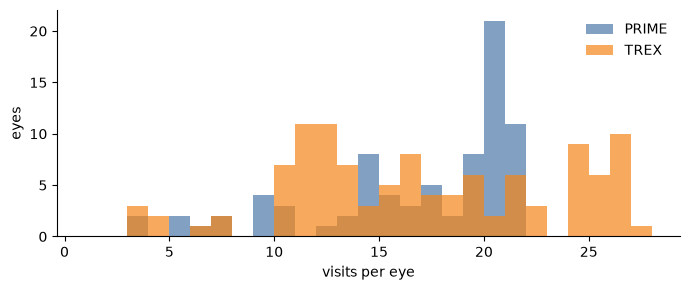

In [4]:
vol = (img.groupby(['study', 'cohort', 'patient', 'eye', 'eye_key', 'vol_key', 'visit', 'visit_num'], dropna=False)
          .agg(n_scans=('path', 'size'), min_idx=('scan_idx', 'min'), max_idx=('scan_idx', 'max'))
          .reset_index().sort_values(['eye_key', 'visit_num']))
vol['visit_order'] = vol.groupby('eye_key').cumcount() + 1

bad_tok = vol[vol.visit_num.isna()]
if len(bad_tok):
    flag('visit names', f'unparsed visit folder names: {sorted(bad_tok.visit.unique())[:10]}', len(bad_tok))
mixed = vol.assign(t=vol.visit.str[0].str.upper()).groupby('eye_key').t.nunique()
if (mixed > 1).any():
    flag('visit names', 'eyes mixing W and V visit folders', int((mixed > 1).sum()))

print('B-scans per volume:'); display(vol.n_scans.value_counts().sort_index().rename('volumes'))
print('B-scan index range on disk:', img.scan_idx.min(), 'to', img.scan_idx.max())
off = vol[vol.n_scans != 49]
if len(off):
    flag('scans per volume', 'volumes without exactly 49 B-scans', len(off)); display(off.head(20))
gaps = vol[(vol.max_idx - vol.min_idx + 1) != vol.n_scans]
if len(gaps):
    flag('scans per volume', 'volumes with missing or duplicated scan numbers', len(gaps)); display(gaps.head(10))

eye = (vol.groupby(['study', 'eye_key'])
          .agg(n_visits=('visit', 'size'), first_visit=('visit', 'first'), last_visit=('visit', 'last'),
               first_num=('visit_num', 'first'), last_num=('visit_num', 'last'))
          .reset_index())
print('Visits per eye:'); display(eye.groupby('study').n_visits.describe().round(1))
print('PRIME follow-up span in weeks:'); display((eye.loc[eye.study == 'PRIME', 'last_num'] - eye.loc[eye.study == 'PRIME', 'first_num']).describe().round(1))
few = eye[eye.n_visits < 2]
if len(few):
    flag('visits per eye', 'eyes with fewer than 2 visits on disk', len(few)); display(few)

vol.to_csv(OUT / 'volume_table.csv', index=False)
eye.to_csv(OUT / 'eye_table.csv', index=False)

fig, ax = plt.subplots(figsize=(7, 3))
for s, c in [('PRIME', '#4C78A8'), ('TREX', '#F58518')]:
    ax.hist(eye.loc[eye.study == s, 'n_visits'], bins=range(1, int(eye.n_visits.max()) + 2), alpha=0.7, label=s, color=c)
ax.set_xlabel('visits per eye'); ax.set_ylabel('eyes'); ax.legend(frameon=False); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.savefig(OUT / 'visits_per_eye.png', dpi=150); plt.show()

## Step 3: Find the label files
The images and the labels are separate files in OLIVES. This searches the whole project folder for CSV/Excel files and recognizes:
- the **biomarker file** (`Biomarker_Clinical_Data_Images.csv`: path, scan number, 16 biomarkers, BCVA, CST, IDs)
- the **clinical file** (`Clinical_Data_Images.xlsx`: path, BCVA, CST, IDs for every B-scan)

In [5]:
search = [d for d in (LABEL_ROOT, PROJECT) if d.exists()]
cands = {p for d in search for p in d.rglob('*')
         if p.suffix.lower() in ('.csv', '.xlsx', '.xls') and OUT not in p.parents and not p.name.startswith(('~$', '.'))}
# the ML-centric copies are the documented ones, so they are checked first
cands = sorted(cands, key=lambda p: (0 if 'ml_centric' in str(p).lower() else 1, str(p)))
BIO_FILE = CLIN_FILE = None
for p in cands:
    try:
        h = read_table(p, nrows=5)
    except ImportError as e:
        print(f'  {p.name}: needs a package to read ({e}); run  %pip install openpyxl'); continue
    except Exception as e:
        print(f'  {p.name}: could not read ({type(e).__name__})'); continue
    cl = [str(c).lower() for c in h.columns]
    has_path = any('path' in c for c in cl)
    has_scan = any(c.startswith('scan') for c in cl)
    has_bm   = any(k in c for c in cl for k in ('irf', 'drt', 'hrf', 'vitreous'))
    has_clin = any('bcva' in c for c in cl) and any('cst' in c for c in cl)
    print(f'{p.parent.name}/{p.name}  | {len(h.columns)} cols | path={has_path} scan={has_scan} biomarkers={has_bm} clinical={has_clin}')
    if has_path and has_scan and has_bm and BIO_FILE is None:
        BIO_FILE = p
    elif has_path and has_clin and not has_bm and CLIN_FILE is None:
        CLIN_FILE = p

print('\nBiomarker file:', BIO_FILE)
print('Clinical file :', CLIN_FILE)
if BIO_FILE is None:
    flag('labels', 'biomarker label file not found under the project folder')
    print("""
The biomarker labels are not in the folders searched. The image download does not always include them.
Look for "Biomarker_Clinical_Data_Images.csv" and "Clinical_Data_Images.xlsx" (folder "ml_centric_labels",
next to "full_labels") on the Zenodo record https://zenodo.org/records/7105232 or via the label link in
https://github.com/olivesgatech/OLIVES_Dataset. Put them anywhere inside the project folder and re-run from this cell.
Steps 4, 5 and 7 are skipped until then; the other steps still run.""")
if CLIN_FILE is None:
    flag('labels', 'clinical label file not found under the project folder')

# full_labels/ holds files with the same names: are they the same as the ml_centric copies?
for f in (BIO_FILE, CLIN_FILE):
    if f is None:
        continue
    twins = [p for p in cands if p.name == f.name and p != f]
    for t in twins:
        same = hashlib.md5(t.read_bytes()).hexdigest() == hashlib.md5(f.read_bytes()).hexdigest()
        print(f'{f.parent.name}/{f.name} vs {t.parent.name}/{t.name}: {"identical" if same else "DIFFERENT"}')
        if not same:
            flag('labels', f'{f.name} differs between {f.parent.name} and {t.parent.name}')

ml_centric_labels/Biomarker_Clinical_Data_Images.csv  | 22 cols | path=True scan=True biomarkers=True clinical=True
  Clinical_Data_Images.xlsx: needs a package to read (`Import openpyxl` failed.  Use pip, conda, or your preferred package management tool to install the openpyxl package.); run  %pip install openpyxl
sample_data/Stocks.csv  | 1 cols | path=False scan=False biomarkers=False clinical=False
sample_data/data_x_x2_x3.csv  | 1 cols | path=False scan=False biomarkers=False clinical=False
sample_data/msft.csv  | 7 cols | path=False scan=False biomarkers=False clinical=False
data/umath-validation-set-arccos.csv  | 4 cols | path=False scan=False biomarkers=False clinical=False
data/umath-validation-set-arccosh.csv  | 4 cols | path=False scan=False biomarkers=False clinical=False
data/umath-validation-set-arcsin.csv  | 4 cols | path=False scan=False biomarkers=False clinical=False
data/umath-validation-set-arcsinh.csv  | 4 cols | path=False scan=False biomarkers=False clinical=Fals

In [6]:
# The full trial sheets (OCT-DR.xlsx = PRIME, OCT-DME.xlsx = TREX-DME): which sheets and columns exist?
# Looking for anything useful later: visit dates/weeks, injections, DRSS, treatment arm.
for p in sorted(LABEL_ROOT.rglob('OCT-*.xls*')) if LABEL_ROOT.exists() else []:
    try:
        sheets = pd.read_excel(p, sheet_name=None, nrows=3)
    except Exception as e:
        print(p.name, '-> could not read:', type(e).__name__, e); continue
    for name, h in sheets.items():
        print(f'\n{p.name} / sheet "{name}": {h.shape[1]} columns')
        print('  ', [str(c) for c in h.columns][:60])
        hits = [str(c) for c in h.columns if re.search(r'inject|ivt|dose|date|week|visit|drss|arm|cohort', str(c), re.I)]
        if hits:
            print('   treatment/time columns:', hits)

OCT-DME.xlsx -> could not read: ImportError `Import openpyxl` failed.  Use pip, conda, or your preferred package management tool to install the openpyxl package.
OCT-DR.xlsx -> could not read: ImportError `Import openpyxl` failed.  Use pip, conda, or your preferred package management tool to install the openpyxl package.


## Step 4: Check the biomarker labels
Expect 9,408 rows = 96 eyes × 2 labeled visits (first and last) × 49 B-scans, and 16 binary biomarker columns.

In [7]:
bio = None
if BIO_FILE is not None:
    bio = read_table(BIO_FILE)
    bio.columns = [str(c).strip() for c in bio.columns]
    bio = bio.loc[:, ~bio.columns.str.startswith('Unnamed')]
    path_col  = next(c for c in bio.columns if 'path' in c.lower())
    scan_col  = next(c for c in bio.columns if c.lower().startswith('scan'))
    meta_cols = [c for c in bio.columns if c not in (path_col, scan_col) and re.search(r'eye|bcva|cst|patient', c, re.I)]
    bm_cols   = [c for c in bio.columns if c not in [path_col, scan_col] + meta_cols]
    print(f'Rows: {len(bio):,} (expected 9,408)')
    print(f'Biomarker columns ({len(bm_cols)}, expected 16):', bm_cols)
    print('ID / clinical columns:', meta_cols)
    if len(bio) != 9408: flag('biomarker labels', f'{len(bio)} rows instead of 9,408')
    if len(bm_cols) != 16: flag('biomarker labels', f'{len(bm_cols)} biomarker columns instead of 16')

    # values must be 0/1
    vals = bio[bm_cols].apply(pd.to_numeric, errors='coerce')
    text = (vals.isna() & bio[bm_cols].notna()).sum()
    nans = bio[bm_cols].isna().sum()
    other_vals = {c: sorted(set(vals[c].dropna().unique()) - {0, 1}) for c in bm_cols}
    other_vals = {c: v for c, v in other_vals.items() if v}
    if text.sum(): flag('biomarker labels', f'non-numeric entries: {text[text > 0].to_dict()}', int(text.sum()))
    if nans.sum(): flag('biomarker labels', f'empty entries: {nans[nans > 0].to_dict()}', int(nans.sum()))
    if other_vals: flag('biomarker labels', f'values other than 0/1: {other_vals}')
    bio[bm_cols] = vals

    # parse paths -> keys
    parsed = bio[path_col].astype(str).str.replace('\\', '/', regex=False).map(lambda s: parse_parts(s.split('/')))
    if parsed.isna().any():
        flag('biomarker labels', 'paths that do not follow trial/patient/visit/eye/file', int(parsed.isna().sum()))
    bio = bio.join(pd.DataFrame([d for d in parsed if d is not None], index=bio.index[parsed.notna()]))
    bio['study']     = bio.trial.map(study_of)
    bio['scan_idx']  = pd.to_numeric(bio[scan_col], errors='coerce') - 1        # 'Scan (n/49)' is 1-based, files are 0-based
    bio['visit_num'] = bio.visit.map(visit_number)
    bio['eye_key']   = bio.study + '|' + bio.patient + '|' + bio.eye
    bio['vol_key']   = bio.eye_key + '|' + bio.visit
    stem_agree = (bio.file.map(lambda f: scan_from_stem(Path(str(f)).stem)) == bio.scan_idx).mean()
    print(f'Scan column agrees with the number in the file name for {stem_agree:.1%} of rows')

    # duplicates and volume completeness
    key = ['study', 'patient', 'visit', 'eye', 'scan_idx']
    dup = bio.duplicated(key, keep=False)
    if dup.any(): flag('biomarker labels', 'the same B-scan labelled more than once', int(dup.sum())); display(bio.loc[dup, [path_col, scan_col]].head(10))
    per_vol = bio.groupby('vol_key').size()
    if (per_vol != 49).any(): flag('biomarker labels', 'labelled volumes without 49 rows', int((per_vol != 49).sum())); display(per_vol[per_vol != 49])

    # match every label row to an image on disk
    disk = img[key + ['path']].drop_duplicates(key)
    m = bio.merge(disk.rename(columns={'path': 'img_path'}), on=key, how='left')
    bio['img_path'] = m['img_path'].values
    miss = bio.img_path.isna()
    print(f'Label rows matched to an image on disk: {(~miss).mean():.2%}')
    if miss.any():
        flag('label-image match', 'label rows with no matching image on disk', int(miss.sum()))
        print('Examples:'); display(bio.loc[miss, [path_col, 'patient', 'visit', 'eye', 'scan_idx']].head(10))
        print('Patients in labels but not on disk:', sorted(set(bio.loc[miss, 'study'] + '|' + bio.loc[miss, 'patient']) - set(img.pat_key))[:15])

    # first / last labelled visit per eye, and are they the first / last visits on disk?
    lab_eye = bio.groupby('eye_key').agg(n_lab_visits=('visit', 'nunique'), first_lab=('visit_num', 'min'), last_lab=('visit_num', 'max'))
    print('Labelled visits per eye:'); display(lab_eye.n_lab_visits.value_counts().rename('eyes'))
    if (lab_eye.n_lab_visits != 2).any(): flag('biomarker labels', 'eyes without exactly 2 labelled visits', int((lab_eye.n_lab_visits != 2).sum()))
    cmp = lab_eye.join(eye.set_index('eye_key')[['first_num', 'last_num', 'n_visits']], how='outer')
    no_lab = cmp[cmp.n_lab_visits.isna()].index.tolist()
    no_img = cmp[cmp.n_visits.isna()].index.tolist()
    if no_lab: flag('label-image match', f'eyes on disk with no biomarker labels: {no_lab[:10]}', len(no_lab))
    if no_img: flag('label-image match', f'labelled eyes not on disk: {no_img[:10]}', len(no_img))
    both = cmp.dropna()
    nf = both[both.first_lab != both.first_num]; nl = both[both.last_lab != both.last_num]
    if len(nf): flag('labelled visits', 'labelled "first" visit is not the first visit on disk', len(nf)); display(nf.head(10))
    if len(nl): flag('labelled visits', 'labelled "last" visit is not the last visit on disk', len(nl)); display(nl.head(10))
    bio = bio.join(lab_eye[['first_lab', 'last_lab']], on='eye_key')
    bio['timepoint'] = np.select([bio.visit_num == bio.first_lab, bio.visit_num == bio.last_lab], ['first', 'last'], 'middle')

    # IDs and clinical values must be constant where they should be
    for c in meta_cols:
        lvl = 'eye_key' if re.search(r'eye|patient', c, re.I) else 'vol_key'
        n_inc = int((bio.groupby(lvl)[c].nunique() > 1).sum())
        if n_inc: flag('biomarker labels', f'"{c}" varies within one {lvl.split("_")[0]}', n_inc)

    bio.to_csv(OUT / 'biomarker_labels_clean.csv', index=False)
    print('Saved biomarker_labels_clean.csv')

Rows: 9,408 (expected 9,408)
Biomarker columns (16, expected 16): ['Atrophy / thinning of retinal layers', 'Disruption of EZ', 'DRIL', 'IR hemorrhages', 'IR HRF', 'Partially attached vitreous face', 'Fully attached vitreous face', 'Preretinal tissue/hemorrhage', 'Vitreous debris', 'VMT', 'DRT/ME', 'Fluid (IRF)', 'Fluid (SRF)', 'Disruption of RPE', 'PED (serous)', 'SHRM']
ID / clinical columns: ['Eye_ID', 'BCVA', 'CST', 'Patient_ID']
[FLAG] biomarker labels: empty entries: {'Partially attached vitreous face': 6, 'Fully attached vitreous face': 3, 'Preretinal tissue/hemorrhage': 2, 'Vitreous debris': 8}  (n=19)
Scan column agrees with the number in the file name for 100.0% of rows
Label rows matched to an image on disk: 100.00%
Labelled visits per eye:


n_lab_visits
2    96
Name: eyes, dtype: int64

[FLAG] label-image match: eyes on disk with no biomarker labels: ['PRIME|01-001|OD', 'PRIME|01-002|OS', 'PRIME|01-012|OS', 'PRIME|01-013|OS', 'PRIME|01-014|OD', 'PRIME|01-020|OD', 'PRIME|01-023|OS', 'PRIME|01-025|OS', 'PRIME|01-026|OS', 'PRIME|01-027|OD']  (n=94)
Saved biomarker_labels_clean.csv


## Step 5: Check the clinical labels
BCVA and CST for every B-scan of every visit. Known issue: Patient 79 has BCVA/CST only at the first and last visit.

In [8]:
clin_visit = None
if CLIN_FILE is not None:
    clin = read_table(CLIN_FILE)
    clin.columns = [str(c).strip() for c in clin.columns]
    cpath = next(c for c in clin.columns if 'path' in c.lower())
    bcva  = next(c for c in clin.columns if 'bcva' in c.lower())
    cst   = next(c for c in clin.columns if 'cst' in c.lower())
    print(f'Rows: {len(clin):,} vs B-scans on disk: {len(img):,}')
    parsed = clin[cpath].astype(str).str.replace('\\', '/', regex=False).map(lambda s: parse_parts(s.split('/')))
    if parsed.isna().any(): flag('clinical labels', 'unparseable paths', int(parsed.isna().sum()))
    clin = clin.join(pd.DataFrame([d for d in parsed if d is not None], index=clin.index[parsed.notna()]))
    clin['study']   = clin.trial.map(study_of)
    clin['vol_key'] = clin.study + '|' + clin.patient + '|' + clin.eye + '|' + clin.visit
    for c in (bcva, cst):
        clin[c] = pd.to_numeric(clin[c], errors='coerce')

    v_disk, v_clin = set(img.vol_key), set(clin.vol_key.dropna())
    print(f'Volumes on disk with clinical rows: {len(v_disk & v_clin)}/{len(v_disk)}')
    if v_disk - v_clin: flag('clinical labels', 'volumes on disk with no clinical rows', len(v_disk - v_clin))
    if v_clin - v_disk: flag('clinical labels', 'clinical volumes not on disk', len(v_clin - v_disk))

    clin_visit = clin.groupby('vol_key').agg(BCVA=(bcva, 'first'), CST=(cst, 'first'),
                                             BCVA_n=(bcva, 'nunique'), CST_n=(cst, 'nunique')).reset_index()
    if (clin_visit[['BCVA_n', 'CST_n']] > 1).any(axis=None):
        flag('clinical labels', 'BCVA or CST varies within one visit', int((clin_visit[['BCVA_n', 'CST_n']] > 1).any(axis=1).sum()))
    clin_visit['patient'] = clin_visit.vol_key.str.split('|').str[:2].str.join('|')
    missing = clin_visit[clin_visit[['BCVA', 'CST']].isna().any(axis=1)]
    if len(missing):
        flag('clinical labels', 'visits missing BCVA or CST', len(missing))
        display(missing.groupby('patient').size().rename('visits missing BCVA/CST').sort_values(ascending=False).head(10))
    oor = clin_visit[(clin_visit.BCVA < 0) | (clin_visit.BCVA > 100) | (clin_visit.CST < 100) | (clin_visit.CST > 1300)]
    if len(oor): flag('clinical labels', 'BCVA outside 0-100 or CST outside 100-1300', len(oor)); display(oor.head())
    display(clin_visit[['BCVA', 'CST']].describe().round(1))
    clin_visit.drop(columns=['BCVA_n', 'CST_n']).to_csv(OUT / 'clinical_by_visit.csv', index=False)
    print('Saved clinical_by_visit.csv (one row per visit, used later for label-shift correction)')

## Step 6: Find duplicate volumes
Known issue: some visits contain exactly the same scans as an earlier visit (e.g. Patient 61, W8 and W12). Each volume gets a fingerprint from the bytes of its first, middle and last B-scan; equal fingerprints = duplicated volume.

In [9]:
def md5(p):
    return hashlib.md5(Path(p).read_bytes()).hexdigest()

sig = {}
for vk, g in img.sort_values('scan_idx').groupby('vol_key'):
    ps = g.path.tolist()
    sig[vk] = '|'.join(md5(p) for p in (ps[0], ps[len(ps) // 2], ps[-1]))
vol['fingerprint'] = vol.vol_key.map(sig)

dups = vol[vol.duplicated('fingerprint', keep=False)].sort_values(['fingerprint', 'eye_key', 'visit_num'])
if len(dups):
    groups = dups.groupby('fingerprint')
    cross_eye = sum(g.eye_key.nunique() > 1 for _, g in groups)
    flag('duplicate volumes', f'{groups.ngroups} sets of identical volumes ({cross_eye} span different eyes)', len(dups))
    display(dups[['eye_key', 'visit', 'visit_order', 'n_scans']].head(30))
    dups.to_csv(OUT / 'duplicate_volumes.csv', index=False)
else:
    print('No duplicated volumes found.')

[FLAG] duplicate volumes: 187 sets of identical volumes (183 span different eyes)  (n=374)


,eye_key,visit,visit_order,n_scans
1757,TREX|0243GOD|OD,V10,10,51
3028,TREX|0243TOS|OD,V10,10,51
1394,TREX|0204GOS|OS,V4,4,51
1978,TREX|0204MOD|OS,V4,4,51
2274,TREX|0222MOS|OD,V21,21,51
2727,TREX|0222TOD|OD,V12,12,51
1322,TREX|0201GOD|OS,V4,4,51
2543,TREX|0201TOS|OS,V4,4,51
1409,TREX|0213GOD|OD,V9,9,51
2655,TREX|0213TOS|OD,V14,14,51


## Step 7: Biomarker prevalence: first vs last visit
This is the first result of the project. A large drop for fluid biomarkers (IRF, DRT/ME) between first and last visit is the **label shift** the study is about. Reported per B-scan and per eye (eye positive = biomarker in at least one of its 49 B-scans).

Study biomarkers -> columns: {'IRF': 'Fluid (IRF)', 'DRT/ME': 'DRT/ME', 'IRHRF': 'IR HRF', 'FAVF': 'Fully attached vitreous face', 'PAVF': 'Partially attached vitreous face'}


,pct_scans_first,pct_scans_last,change_pp_scans,pos_eyes_first,pos_eyes_last,usable,study_role
biomarker,,,,,,,
IR HRF,77.1,57.7,-19.4,96.0,96.0,True,treatment-responsive
Fluid (IRF),58.0,28.9,-29.0,92.0,82.0,True,treatment-responsive
Fully attached vitreous face,57.5,53.5,-4.0,69.0,65.0,True,control
DRT/ME,47.9,15.9,-32.0,70.0,44.0,True,treatment-responsive
Vitreous debris,33.8,26.6,-7.2,86.0,78.0,True,NaN
Partially attached vitreous face,32.3,31.2,-1.2,57.0,53.0,True,control
Preretinal tissue/hemorrhage,8.2,8.9,0.7,25.0,23.0,True,NaN
IR hemorrhages,6.4,1.5,-5.0,46.0,21.0,True,NaN
Fluid (SRF),4.5,0.5,-4.0,26.0,3.0,False,NaN


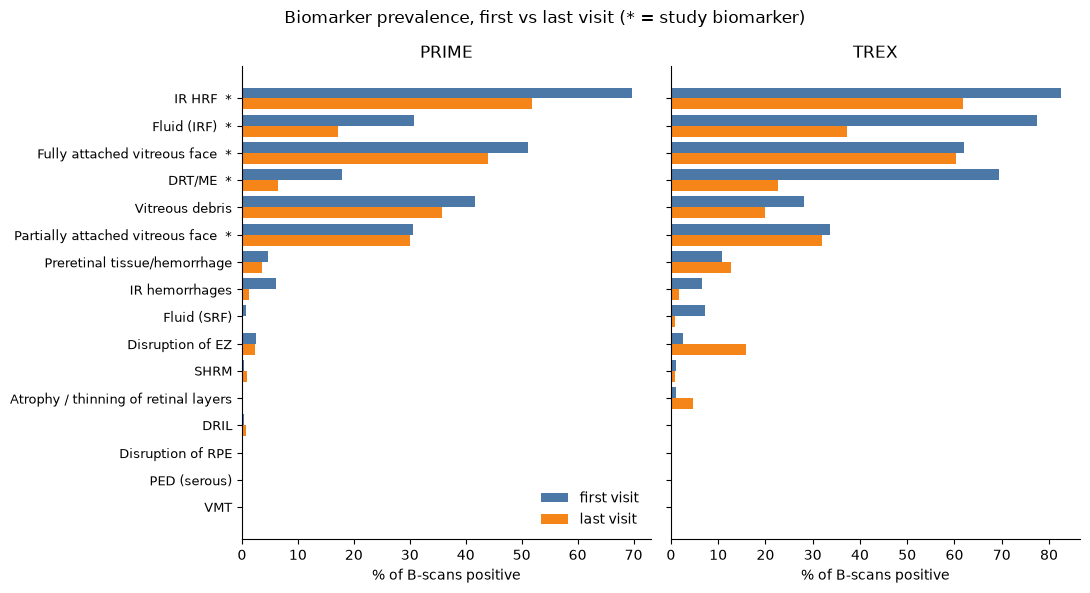

In [10]:
prev = wide = None
if bio is not None:
    TARGETS = {'IRF': ('irf',), 'DRT/ME': ('drt',), 'IRHRF': ('hrf',), 'FAVF': ('fully',), 'PAVF': ('partially',)}
    ROLE = {'IRF': 'treatment-responsive', 'DRT/ME': 'treatment-responsive', 'IRHRF': 'treatment-responsive',
            'FAVF': 'control', 'PAVF': 'control'}
    target_col = {}
    for name, keys in TARGETS.items():
        hits = [c for c in bm_cols if all(k in c.lower() for k in keys)]
        target_col[name] = hits[0] if hits else None
        if len(hits) != 1: flag('target biomarkers', f'{name}: matched columns {hits}')
    print('Study biomarkers -> columns:', target_col)

    lab = bio[bio.timepoint.isin(['first', 'last'])]
    recs = []
    for cohort, g in [('ALL', lab)] + list(lab.groupby('study')):
        for tp, gt in g.groupby('timepoint'):
            eye_any = gt.groupby('eye_key')[bm_cols].max()
            for c in bm_cols:
                recs.append(dict(biomarker=c, cohort=cohort, timepoint=tp,
                                 n_scans=int(gt[c].notna().sum()), pos_scans=int(gt[c].sum()),
                                 n_eyes=int(eye_any[c].notna().sum()), pos_eyes=int(eye_any[c].sum())))
    prev = pd.DataFrame(recs)
    prev['pct_scans'] = 100 * prev.pos_scans / prev.n_scans
    prev['pct_eyes']  = 100 * prev.pos_eyes / prev.n_eyes
    prev.to_csv(OUT / 'prevalence_long.csv', index=False)

    w = prev[prev.cohort == 'ALL'].pivot(index='biomarker', columns='timepoint', values=['pos_scans', 'n_scans', 'pct_scans', 'pos_eyes', 'pct_eyes'])
    w.columns = [f'{a}_{b}' for a, b in w.columns]
    w['change_pp_scans'] = w.pct_scans_last - w.pct_scans_first
    # provisional rule: enough positives AND negatives at the first visit (training) and some positives at the last visit (testing)
    w['usable'] = ((w.pos_scans_first >= 300) & (w.n_scans_first - w.pos_scans_first >= 300)
                   & (w.pos_eyes_first >= 10) & (w.pos_eyes_last >= 5))
    w['study_role'] = w.index.map({v: ROLE[k] for k, v in target_col.items() if v})
    wide = w.sort_values('pct_scans_first', ascending=False)
    wide.to_csv(OUT / 'prevalence_first_vs_last.csv')
    display(wide[['pct_scans_first', 'pct_scans_last', 'change_pp_scans', 'pos_eyes_first', 'pos_eyes_last', 'usable', 'study_role']].round(1))

    for name, c in target_col.items():
        if c is not None and not wide.loc[c, 'usable']:
            flag('target biomarkers', f'{name} fails the provisional "usable" rule')

    # figure: B-scan prevalence first vs last, per trial
    order = wide.index[::-1]
    fig, axes = plt.subplots(1, 2, figsize=(11, 6), sharey=True)
    for ax, s in zip(axes, ['PRIME', 'TREX']):
        d = prev[prev.cohort == s].pivot(index='biomarker', columns='timepoint', values='pct_scans').reindex(order)
        y = np.arange(len(d))
        ax.barh(y + 0.2, d.get('first', 0), height=0.4, color='#4C78A8', label='first visit')
        ax.barh(y - 0.2, d.get('last', 0), height=0.4, color='#F58518', label='last visit')
        ax.set_yticks(y, [f'{b}  *' if b in target_col.values() else b for b in d.index], fontsize=9)
        ax.set_title(s); ax.set_xlabel('% of B-scans positive'); ax.spines[['top', 'right']].set_visible(False)
    axes[0].legend(frameon=False, loc='lower right')
    fig.suptitle('Biomarker prevalence, first vs last visit (* = study biomarker)')
    plt.tight_layout(); plt.savefig(OUT / 'prevalence_first_vs_last.png', dpi=150); plt.show()

## Step 8: Image properties and visual checks
1. Size, a bit of depth and intensity of a random sample of B-scans per trial.
2. Five B-scans across one volume, to check that scan numbers run in spatial order (fovea near the middle).
3. For each study biomarker, labeled examples, to check by eye that the labels match the images.

study  size     mode  dtype
PRIME  504x496  L     uint8    144
       768x768  L     uint8      3
                RGB   uint8      3
TREX   504x496  L     uint8    144
       768x768  L     uint8      2
                RGB   uint8      4
Name: images, dtype: int64

study       PRIME   TREX
vmin count  150.0  150.0
     mean     0.0    0.0
     std      0.0    0.0
     min      0.0    0.0
     25%      0.0    0.0
     50%      0.0    0.0
     75%      0.0    0.0
     max      0.0    0.0
vmax count  150.0  150.0
     mean   255.0  255.0
     std      0.0    0.0
     min    255.0  255.0
     25%    255.0  255.0
     50%    255.0  255.0
     75%    255.0  255.0
     max    255.0  255.0
mean count  150.0  150.0
     mean    46.2   46.1
     std     16.9   18.1
     min     21.7   21.7
     25%     37.8   37.4
     50%     42.7   43.6
     75%     48.2   49.3
     max    141.2  159.7

[FLAG] image properties: more than one image size: ['504x496', '768x768']
[FLAG] image properties: more than one colour mode: ['L', 'RGB']


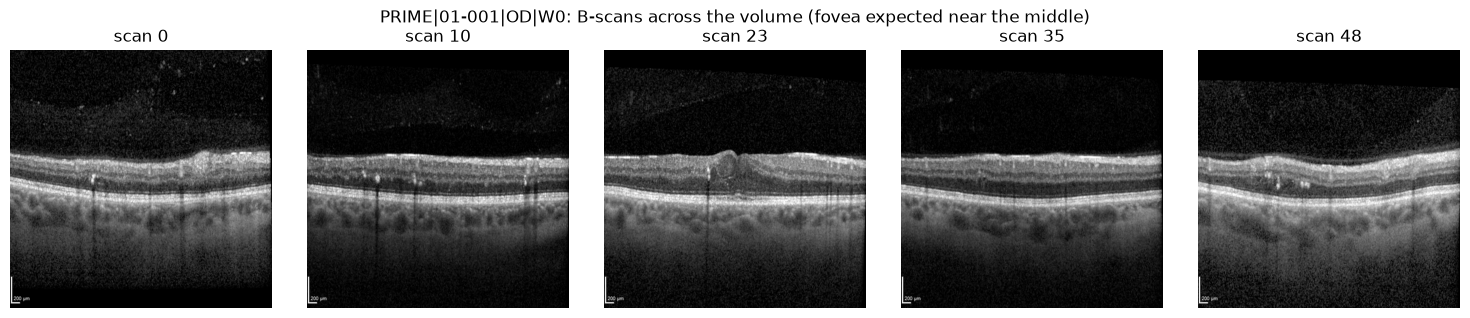

In [11]:
def gray(p):
    with Image.open(p) as im:
        return np.asarray(im.convert('L'))

sample = pd.concat([g.sample(min(150, len(g)), random_state=SEED) for _, g in img.groupby('study')])
props = []
for r in sample.itertuples():
    with Image.open(r.path) as im:
        a = np.asarray(im)
        props.append(dict(study=r.study, size=f'{im.width}x{im.height}', mode=im.mode, dtype=str(a.dtype),
                          vmin=float(a.min()), vmax=float(a.max()), mean=float(a.mean())))
props = pd.DataFrame(props)
display(props.groupby(['study', 'size', 'mode', 'dtype']).size().rename('images'))
display(props.groupby('study')[['vmin', 'vmax', 'mean']].describe().round(1).T)
if props['size'].nunique() > 1:
    flag('image properties', f'more than one image size: {sorted(props["size"].unique())}')
if props['mode'].nunique() > 1:
    flag('image properties', f'more than one colour mode: {sorted(props["mode"].unique())}')

# one volume across its depth
v = vol.iloc[0]
g = img[img.vol_key == v.vol_key].sort_values('scan_idx')
picks = g.iloc[np.linspace(0, len(g) - 1, 5).astype(int)]
fig, axes = plt.subplots(1, 5, figsize=(15, 3.2))
for ax, r in zip(axes, picks.itertuples()):
    ax.imshow(gray(r.path), cmap='gray'); ax.set_title(f'scan {int(r.scan_idx)}'); ax.axis('off')
fig.suptitle(f'{v.vol_key}: B-scans across the volume (fovea expected near the middle)')
plt.tight_layout(); plt.savefig(OUT / 'volume_strip.png', dpi=120); plt.show()

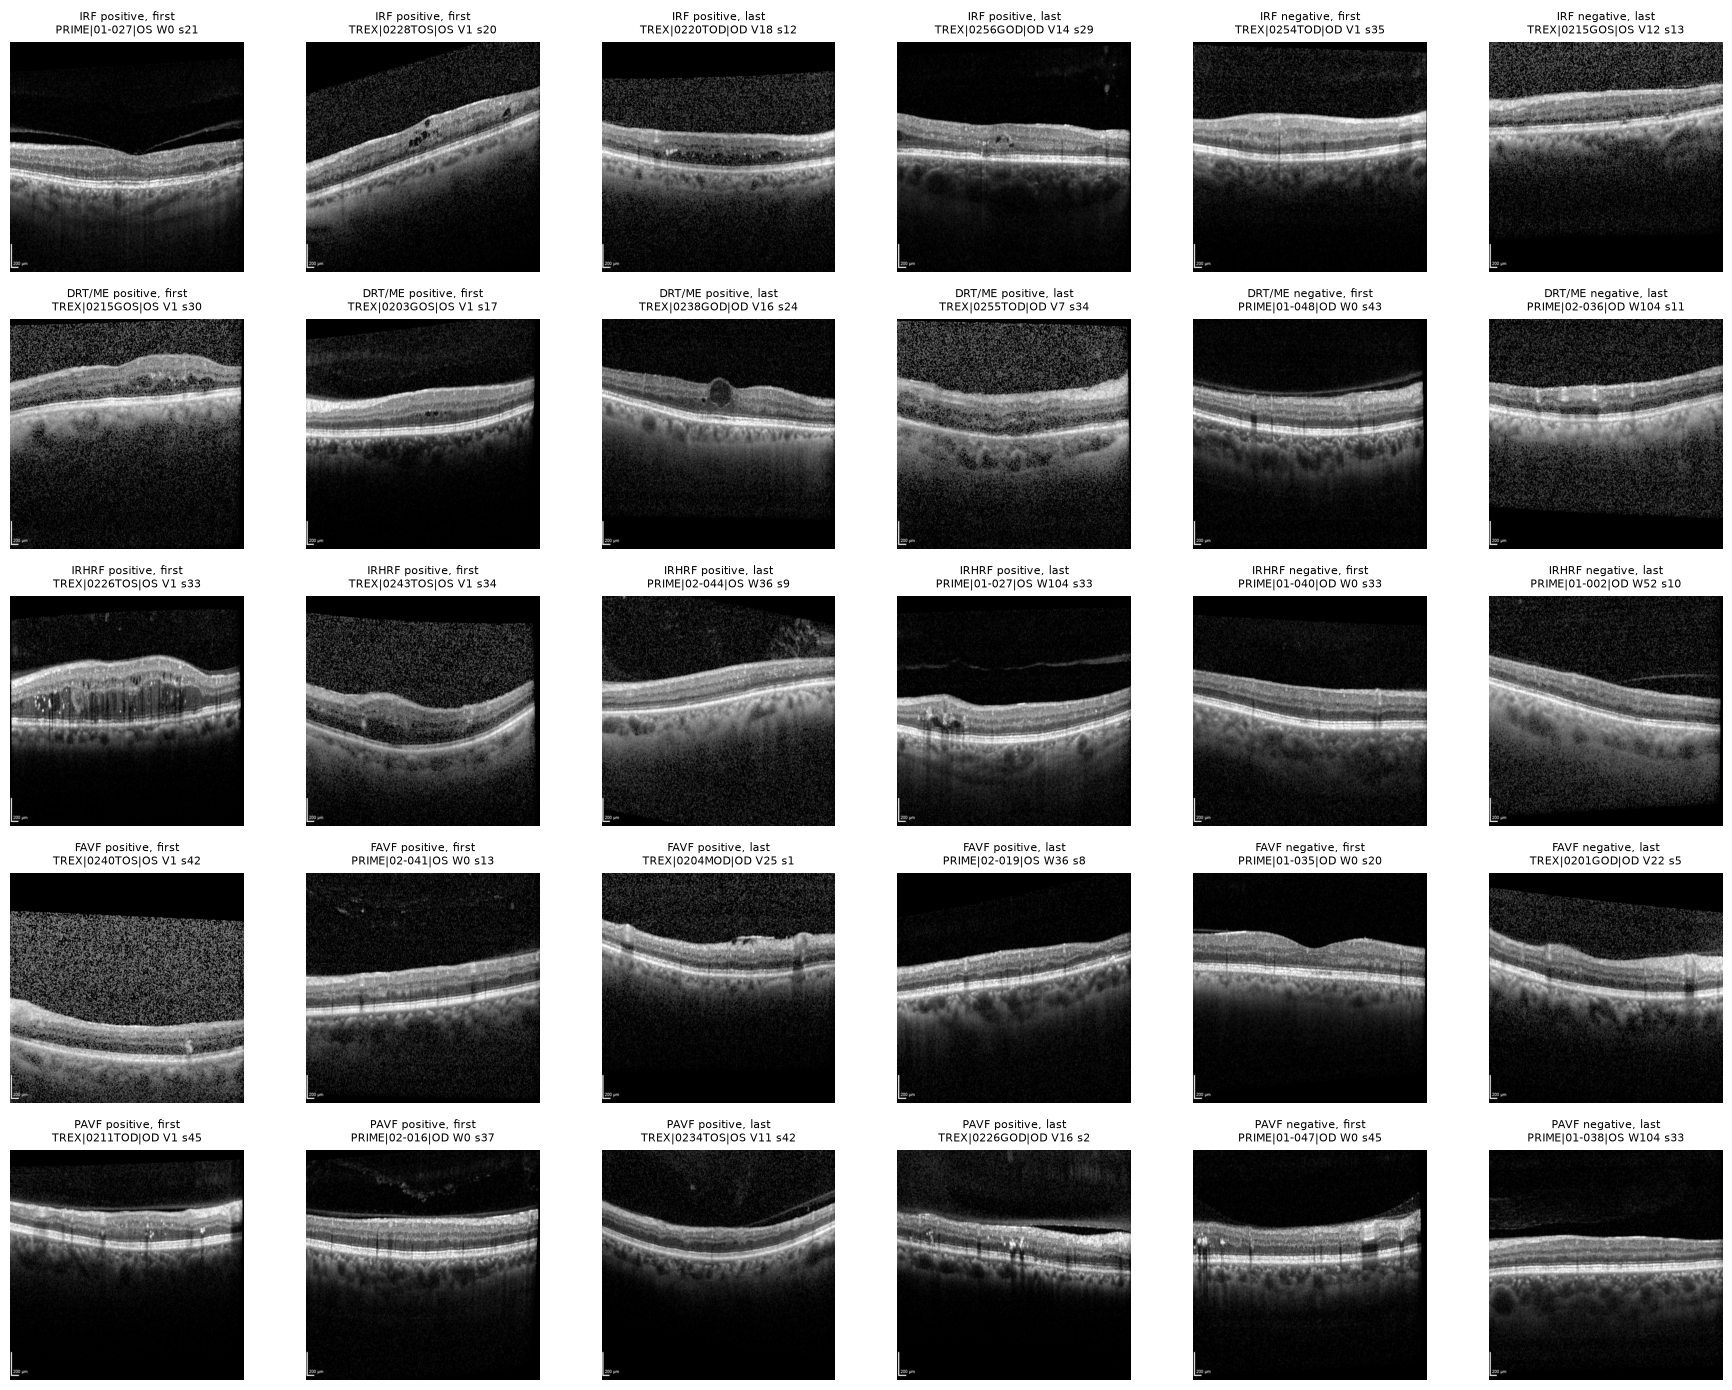

Look at each row: are the "positive" images visibly different from the "negative" ones?


In [12]:
if bio is not None:
    ok = bio[bio.img_path.notna() & bio.timepoint.isin(['first', 'last'])]
    names = [n for n, c in target_col.items() if c is not None]
    cols = [('first', 1, 'positive, first'), ('first', 1, 'positive, first'),
            ('last', 1, 'positive, last'), ('last', 1, 'positive, last'),
            ('first', 0, 'negative, first'), ('last', 0, 'negative, last')]
    fig, axes = plt.subplots(len(names), 6, figsize=(18, 2.8 * len(names)), squeeze=False)
    rng = np.random.default_rng(SEED)
    for i, n in enumerate(names):
        c = target_col[n]
        used = set()
        for j, (tp, val, title) in enumerate(cols):
            ax = axes[i, j]; ax.axis('off')
            pool = ok[(ok.timepoint == tp) & (ok[c] == val) & ~ok.img_path.isin(used)]
            if len(pool) == 0:
                ax.set_title(f'{n}: none', fontsize=9); continue
            r = pool.iloc[rng.integers(len(pool))]; used.add(r.img_path)
            ax.imshow(gray(r.img_path), cmap='gray')
            ax.set_title(f'{n} {title}\n{r.eye_key} {r.visit} s{int(r.scan_idx)}', fontsize=8)
    plt.tight_layout(); plt.savefig(OUT / 'biomarker_examples.png', dpi=110); plt.show()
    print('Look at each row: are the "positive" images visibly different from the "negative" ones?')

## Step 9: Write the summary
Writes `audit_outputs/auto_summary.md` (numbers + every flag) and `audit_outputs/anomalies.csv`. These are the raw material for `data_audit.md` and the paper's Dataset section.

In [13]:
def md_table(df):
    df = df.reset_index()
    out = ['| ' + ' | '.join(map(str, df.columns)) + ' |', '|' + ' --- |' * len(df.columns)]
    for row in df.itertuples(index=False):
        cells = []
        for x in row:
            if isinstance(x, (float, np.floating)):
                cells.append('' if np.isnan(x) else f'{x:.1f}')
            else:
                cells.append(str(x))
        out.append('| ' + ' | '.join(cells) + ' |')
    return '\n'.join(out)

anom = pd.DataFrame(ANOMALIES, columns=['check', 'detail', 'count'])
anom.to_csv(OUT / 'anomalies.csv', index=False)

parts = [f'# OLIVES data audit: auto summary\n\nGenerated {datetime.date.today()} from `{DATA_ROOT}`.',
         '## Counts: expected vs found\n\n' + md_table(EXPECT),
         '## Per trial\n\n' + md_table(per_study),
         '## Visits per eye\n\n' + md_table(eye.groupby('study').n_visits.describe().round(1)),
         f'## Label files\n\n- Biomarker file: `{BIO_FILE}`\n- Clinical file: `{CLIN_FILE}`']
if wide is not None:
    t = wide.loc[[c for c in target_col.values() if c], ['study_role', 'pct_scans_first', 'pct_scans_last', 'change_pp_scans',
                                                        'pos_eyes_first', 'pos_eyes_last', 'usable']]
    parts.append('## Study biomarkers: prevalence first vs last visit (all eyes)\n\n' + md_table(t))
parts.append('## Flags\n\n' + (md_table(anom.set_index('check')) if len(anom) else 'No problems flagged.'))
(OUT / 'auto_summary.md').write_text('\n\n'.join(parts) + '\n')

print(f'{len(anom)} flags raised.')
display(anom)
print('Wrote', OUT / 'auto_summary.md')
print('Outputs:', sorted(p.name for p in OUT.iterdir()))

13 flags raised.


,check,detail,count
0,folder layout,image files outside the trial/patient/visit/eye layout,1800.0
1,counts,"patients: expected 87, found 96",NaN
2,counts,"eyes: expected 96, found 190",NaN
3,counts,"PRIME eyes: expected 40, found 79",NaN
4,counts,"TREX eyes: expected 56, found 111",NaN
5,scans per volume,volumes without exactly 49 B-scans,3118.0
6,scans per volume,volumes with missing or duplicated scan numbers,3118.0
7,labels,clinical label file not found under the project folder,NaN
8,biomarker labels,"empty entries: {'Partially attached vitreous face': 6, 'Fully attached vitre...",19.0
9,label-image match,"eyes on disk with no biomarker labels: ['PRIME|01-001|OD', 'PRIME|01-002|OS'...",94.0


Wrote /Users/parvezali/Research Proposal/audit_outputs/auto_summary.md
Outputs: ['anomalies.csv', 'auto_summary.md', 'biomarker_examples.png', 'biomarker_labels_clean.csv', 'clinical_by_visit.csv', 'duplicate_volumes.csv', 'eye_table.csv', 'image_index.csv', 'prevalence_first_vs_last.csv', 'prevalence_first_vs_last.png', 'prevalence_long.csv', 'visits_per_eye.png', 'volume_strip.png', 'volume_table.csv']
